# 04 — Machine learning (Nixtla `mlforecast`, `skforecast`)

Machine-learning forecasters turn a series into a regression: predict next month from the
**lagged values** (last month, 2, 3, 6, 12 months before), **rolling means**, **calendar
features** (the month of the year) and **static features** (the category). Two choices matter
more than the learner:

- **global vs local**: one model for all series (it can learn "December is high for gifts" from
  every household) or one per series (fits each series' quirks, but from 24–36 rows);
- **recursive vs direct**: forecast month 1, feed it back as a lag for month 2… (one model,
  errors compound) or one model per horizon (no feedback, twelve models).

Plus **target transforms**: each series is scaled by its own mean and spread
(`LocalStandardScaler`) so a €50 health series and a €700 grocery series share a model.

We compare, on notebook 02's protocol (60 households, 48 months, 7 origins, 12 months ahead):

| Name | Library | Model |
|---|---|---|
| LGBM global | mlforecast | LightGBM, recursive, the app's features and settings (`kwak_analytics.forecast`) |
| LGBM global, no scaling | mlforecast | the same without the target transform |
| LGBM global direct | mlforecast | one LightGBM per horizon (`max_horizon=12`) |
| Ridge global | mlforecast | a linear model on the same features |
| skf LGBM global | skforecast | `ForecasterRecursiveMultiSeries`, LightGBM, same lags |
| skf LGBM local | skforecast | `ForecasterRecursive`, one LightGBM per series (a subsample) |

In [1]:
import time
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mlforecast import MLForecast
from mlforecast.lag_transforms import RollingMean
from mlforecast.target_transforms import LocalStandardScaler
from sklearn.linear_model import Ridge

import study

warnings.filterwarnings("ignore")
v = study.bench()
v["category"] = pd.Categorical(v["category"])
stats_cv = study.cached("stats_bench", lambda: None)

def lgbm(seed: int = 20261028) -> lgb.LGBMRegressor:
    # As kwak_analytics.forecast: small trees, deterministic, one thread.
    return lgb.LGBMRegressor(n_estimators=100, learning_rate=0.05, num_leaves=7, min_child_samples=5,
                             deterministic=True, force_row_wise=True, num_threads=1,
                             random_state=seed, verbosity=-1)

FEATURES = dict(
    lags=[1, 2, 3, 6, 12],
    lag_transforms={1: [RollingMean(window_size=3), RollingMean(window_size=6)]},
    date_features=["month"],
)

def ml_cv(models: dict, *, scale: bool = True, direct: bool = False, category: bool = True) -> pd.DataFrame:
    fc = MLForecast(models=models, freq="MS", target_transforms=[LocalStandardScaler()] if scale else None,
                    num_threads=4, **FEATURES)
    cols = ["unique_id", "ds", "y"] + (["category"] if category else [])
    return fc.cross_validation(
        df=v[cols], n_windows=7, h=12, step_size=2,
        static_features=["category"] if category else [], max_horizon=12 if direct else None,
    )

def compute_mlf() -> pd.DataFrame:
    t = time.perf_counter()
    # A linear model cannot read a categorical column: Ridge sees the lags and the month only.
    a = ml_cv({"LGBM global": lgbm()}).merge(
        ml_cv({"Ridge global": Ridge(alpha=1.0)}, category=False).drop(columns="y"),
        on=["unique_id", "ds", "cutoff"],
    )
    b = ml_cv({"LGBM global, no scaling": lgbm()}, scale=False)
    c = ml_cv({"LGBM global direct": lgbm()}, direct=True)
    print(f"mlforecast: {time.perf_counter() - t:.0f} s")
    keys = ["unique_id", "ds", "cutoff"]
    return a.merge(b.drop(columns="y"), on=keys).merge(c.drop(columns="y"), on=keys)

mlf = study.cached("ml_mlforecast", compute_mlf)
mlf.head(3)

,unique_id,ds,cutoff,y,LGBM global,Ridge global,"LGBM global, no scaling",LGBM global direct
0,002/Children,2024-01-01,2023-12-01,237.98,304.172781,316.120607,262.418809,304.172781
1,002/Children,2024-02-01,2023-12-01,328.57,305.587719,338.286860,284.930165,307.751598
2,002/Children,2024-03-01,2023-12-01,415.44,311.880927,340.235015,284.930165,316.880714


## skforecast, global and local

skforecast takes series as columns of a wide frame. We run its global recursive forecaster on
the same series and origins, and its local one (a LightGBM per series) on a 120-series
subsample, because 7 origins × 658 series × a LightGBM each is slow for little insight.

In [2]:
from skforecast.recursive import ForecasterRecursive, ForecasterRecursiveMultiSeries

wide = v.pivot(index="ds", columns="unique_id", values="y").asfreq("MS")
cuts = study.cutoffs(v, n_windows=7, step=2)

def skf_global() -> pd.DataFrame:
    rows = []
    for c in cuts:
        train = wide.loc[:c]
        f = ForecasterRecursiveMultiSeries(estimator=lgbm(), lags=[1, 2, 3, 6, 12], encoding="ordinal",
                                          transformer_series=None)
        f.fit(series=train, suppress_warnings=True)
        p = f.predict(steps=12, suppress_warnings=True)
        p = p.reset_index().rename(columns={"index": "ds", "level": "unique_id", "pred": "skf LGBM global"})
        p["cutoff"] = c
        rows.append(p)
    return pd.concat(rows)

def skf_local(sample: list[str]) -> pd.DataFrame:
    rows = []
    for c in cuts:
        for uid in sample:
            y = wide.loc[:c, uid]
            f = ForecasterRecursive(estimator=lgbm(), lags=[1, 2, 3, 6, 12])
            f.fit(y=y)
            p = f.predict(steps=12)
            rows.append(pd.DataFrame({"unique_id": uid, "ds": p.index, "cutoff": c, "skf LGBM local": p.to_numpy()}))
    return pd.concat(rows)

t0 = time.perf_counter()
skg = study.cached("ml_skf_global", skf_global)
sample = sorted(v["unique_id"].drop_duplicates().sample(120, random_state=1))
skl = study.cached("ml_skf_local", lambda: skf_local(sample))
print(f"skforecast: {time.perf_counter() - t0:.0f} s (0 when cached)")

skforecast: 0 s (0 when cached)


## Global within one household, as the app does

The app has **one household**: its "global" model learns from that household's dozen or so
categories only, not from 60 households. This variant fits one LightGBM per household (same
features, settings and origins), which is what `kwak_analytics.forecast` actually does.

In [3]:
def per_household() -> pd.DataFrame:
    parts = []
    for _, g in v.groupby("household"):
        fc = MLForecast(models={"LGBM per household": lgbm()}, freq="MS",
                        target_transforms=[LocalStandardScaler()], num_threads=1, **FEATURES)
        parts.append(fc.cross_validation(df=g[["unique_id", "ds", "y", "category"]], n_windows=7, h=12,
                                         step_size=2, static_features=["category"]))
    return pd.concat(parts).drop(columns="y")

t0 = time.perf_counter()
mlh = study.cached("ml_per_household", per_household)
print(f"per household: {time.perf_counter() - t0:.0f} s (0 when cached)")

per household: 0 s (0 when cached)


## Results, against the best statistical models and the baseline

In [4]:
keys = ["unique_id", "ds", "cutoff"]
allcv = (
    stats_cv[keys + ["y", "Mean6", "ETS", "ARIMA", "SeasonalNaive"]]
    .merge(mlf.drop(columns="y"), on=keys)
    .merge(skg, on=keys)
    .merge(mlh, on=keys)
)
ML = ["LGBM global", "LGBM per household", "LGBM global, no scaling", "LGBM global direct", "Ridge global",
      "skf LGBM global"]
MODELS = ["Mean6", "ETS", "ARIMA", "SeasonalNaive", *ML]
scores = study.point_scores(allcv, v, MODELS)
study.summary(scores, baseline="Mean6").round(3)

,MASE,MASE median,RMSSE,WAPE,bias,beats baseline
model,,,,,,
LGBM global,0.819,0.707,0.778,0.125,0.007,0.656
ARIMA,0.838,0.747,0.814,0.118,0.006,0.581
ETS,0.850,0.735,0.807,0.112,0.007,0.582
LGBM global direct,0.874,0.759,0.828,0.144,0.009,0.564
Ridge global,0.885,0.753,0.839,0.149,0.013,0.594
LGBM per household,0.909,0.794,0.858,0.145,0.011,0.508
SeasonalNaive,0.935,0.875,0.932,0.126,0.012,0.442
"LGBM global, no scaling",0.938,0.801,0.871,0.122,-0.002,0.518
Mean6,0.944,0.832,0.893,0.174,0.007,0.000


The local forecaster, on its 120-series subsample, with the same models on the same subsample:

In [5]:
sub = allcv[allcv["unique_id"].isin(sample)].merge(skl, on=keys)
study.summary(study.point_scores(sub, v, ["Mean6", "ETS", "LGBM global", "skf LGBM local"]), baseline="Mean6").round(3)

,MASE,MASE median,RMSSE,WAPE,bias,beats baseline
model,,,,,,
ETS,0.778,0.717,0.732,0.095,0.009,0.569
LGBM global,0.785,0.703,0.730,0.110,0.011,0.625
Mean6,0.906,0.830,0.844,0.162,0.012,0.000
skf LGBM local,0.966,0.889,0.867,0.180,0.003,0.405


## Significance

In [6]:
ranks, p, cd = study.friedman_nemenyi(scores)
print(ranks.round(2).to_string())
print(f"Friedman p = {p:.2g}; Nemenyi CD = {cd:.3f}")

model
LGBM global                4.27
ETS                        4.58
ARIMA                      4.74
LGBM global direct         5.30
Ridge global               5.32
LGBM global, no scaling    5.73
Mean6                      5.95
LGBM per household         6.13
SeasonalNaive              6.45
skf LGBM global            6.53
Friedman p = 0; Nemenyi CD = 0.200


## By category

In [7]:
scores["category"] = scores["unique_id"].str.split("/").str[1]
scores.dropna(subset=["mase"]).pivot_table(index="category", columns="model", values="mase")[
    ["Mean6", "ETS", "ARIMA", "LGBM global", "LGBM per household", "Ridge global"]
].round(2)

model,Mean6,ETS,ARIMA,LGBM global,LGBM per household,Ridge global
category,,,,,,
Children,0.78,0.62,0.65,0.55,0.70,0.68
Gifts,1.23,1.30,1.17,1.17,1.19,1.14
Groceries,0.85,0.84,0.84,0.76,0.82,0.78
Health,0.98,0.96,0.98,0.94,1.01,0.97
Home,0.92,0.89,0.88,0.85,0.93,0.88
Housing,0.89,0.06,0.12,0.17,0.47,0.73
Leisure,1.02,0.92,0.80,0.68,0.84,0.78
Miscellaneous,0.82,0.80,0.80,0.77,0.85,0.79
Salaries,1.01,0.67,0.76,0.96,0.99,1.09


## By horizon

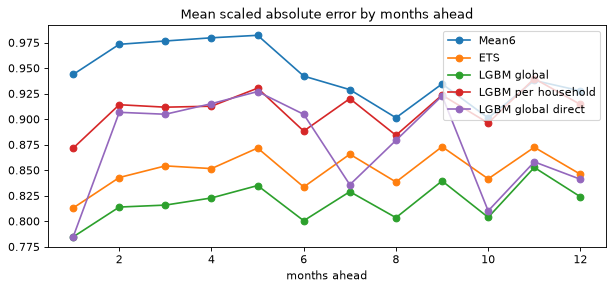

In [8]:
study.by_horizon(allcv, v, ["Mean6", "ETS", "LGBM global", "LGBM per household", "LGBM global direct"]).plot(
    marker="o", title="Mean scaled absolute error by months ahead")
plt.xlabel("months ahead")
plt.show()

## What machine learning brings

- **A LightGBM global across the 60 households is the best single model of the study so far**
  (MASE 0.819, the best average rank, beating the 6-month mean on 66 % of the series-origins):
  pooling households lets it learn the categories' calendar (school, holidays, December) and
  their noise once. It wins on children, groceries, leisure, transport and shopping; ETS keeps
  salaries (a 13th month is a level-and-season pattern ETS models directly) and the property tax.
- **But the app cannot pool households**: it has one. **Global within one household**, as
  `kwak_analytics.forecast` fits it, LightGBM falls to MASE 0.909 and an average rank *below*
  the 6-month mean (6.13 against 5.95): a dozen series of 24–36 months are too few rows for
  trees. It still wins on some series, so keeping it as one candidate among many, behind the
  10 % margin, costs nothing; it should not be expected to be chosen often (it was never chosen
  on the demo).
- **Scaling each series matters**: without the target transform the same global LightGBM falls
  from 0.819 to 0.938 (the trees then split on amounts, not on shapes); skforecast's global
  forecaster, run here without a series transformer, lands in the same place (0.991).
- **Recursive beat direct** (0.819 against 0.874): with 24–36 months, twelve horizon models
  each see too few rows. A linear global model (Ridge, 0.885) is a cheap, respectable second.
- **Local LightGBM** (one per series, skforecast, 120-series subsample) is worst (0.966 against
  0.906 for the 6-month mean on the same subsample): a tree model on 24 rows memorises noise.

A pooled model trained on many households' anonymised series would be the strongest candidate,
but it would need data the app does not have and must not collect (§6, privacy): the
alternative that brings that pooled knowledge without data is a pretrained foundation model,
notebook 05.